# Прогноз страховых расходов

Сравнение LinearRegression и MLPRegressor.

## 1. Импорты и настройки

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)


## 2. Загрузка и анализ данных

In [10]:
df = pd.read_csv('insurance.csv')
df.head()


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


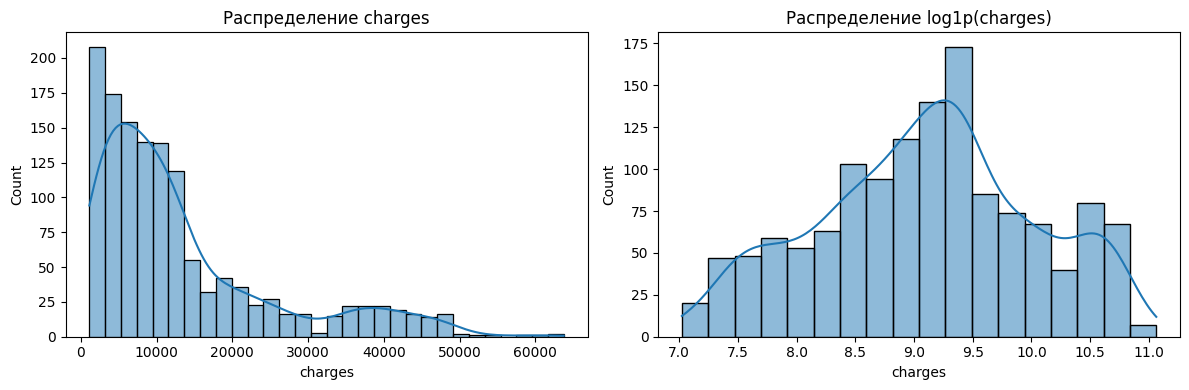

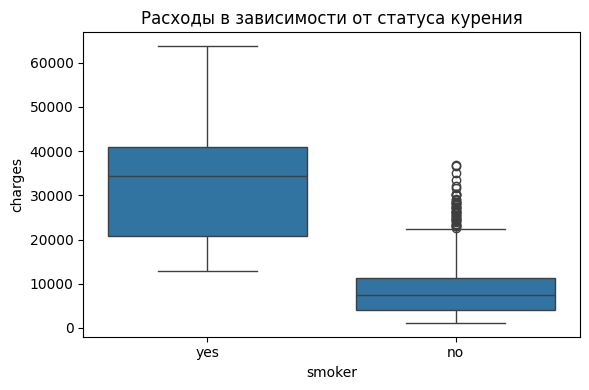

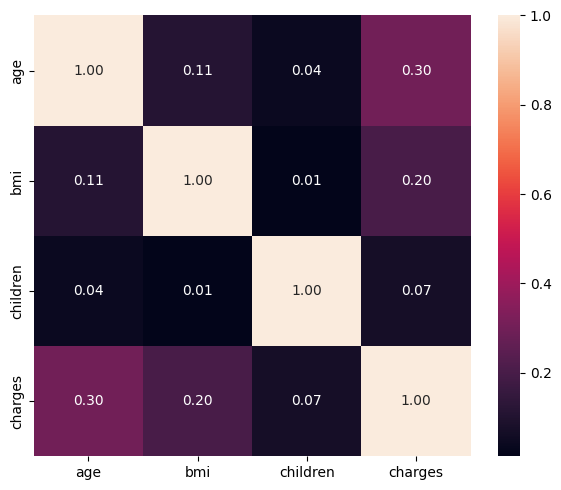

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['charges'], kde=True, ax=axes[0])
axes[0].set_title('Распределение charges')
sns.histplot(np.log1p(df['charges']), kde=True, ax=axes[1])
axes[1].set_title('Распределение log1p(charges)')
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x='smoker', y='charges')
plt.title('Расходы в зависимости от статуса курения')
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 5))
sns.heatmap(df.select_dtypes('number').corr(), annot=True, fmt='.2f')
plt.tight_layout()
plt.show()


## 3. Подготовка данных

In [12]:
X = df.drop(columns='charges')
y = df['charges']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)

num_cols = ['age', 'bmi', 'children']
cat_cols = ['sex', 'smoker', 'region']

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols),
])


## 4. Модели

In [13]:
linear_model = Pipeline([
    ('prep', preprocessor),
    ('model', TransformedTargetRegressor(
        regressor=LinearRegression(),
        func=np.log1p,
        inverse_func=np.expm1,
    )),
])

mlp_model = Pipeline([
    ('prep', preprocessor),
    ('model', TransformedTargetRegressor(
        regressor=MLPRegressor(
            hidden_layer_sizes=(64, 32),
            activation='relu',
            alpha=1e-3,
            learning_rate_init=1e-3,
            max_iter=3000,
            early_stopping=True,
            n_iter_no_change=30,
            random_state=SEED,
        ),
        func=np.log1p,
        inverse_func=np.expm1,
    )),
])


## 5. Оценка моделей

In [14]:
def evaluate_model(name, model):
    model.fit(X_train, y_train)
    predictions = np.clip(model.predict(X_test), 0, None)

    cv_result = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=['r2', 'neg_root_mean_squared_error'],
        n_jobs=-1,
    )

    return {
        'Модель': name,
        'RMSE': np.sqrt(mean_squared_error(y_test, predictions)),
        'MAE': mean_absolute_error(y_test, predictions),
        'R²': r2_score(y_test, predictions),
        'CV R² (среднее)': cv_result['test_r2'].mean(),
        'CV R² (std)': cv_result['test_r2'].std(),
        'CV RMSE (среднее)': -cv_result['test_neg_root_mean_squared_error'].mean(),
        'Предсказания': predictions,
        'CV R² по фолдам': cv_result['test_r2'],
    }

results = [
    evaluate_model('LinearRegression', linear_model),
    evaluate_model('MLPRegressor (64, 32)', mlp_model),
]

results_df = pd.DataFrame([
    {key: value for key, value in result.items()
     if key not in ('Предсказания', 'CV R² по фолдам')}
    for result in results
])
results_df


,Модель,RMSE,MAE,R²,CV R² (среднее),CV R² (std),CV RMSE (среднее)
0,LinearRegression,7814.064026,3888.443159,0.606698,0.504845,0.040377,8427.683821
1,"MLPRegressor (64, 32)",4758.202702,2597.564038,0.854166,0.790058,0.040684,5476.940989


## 6. Графики результатов

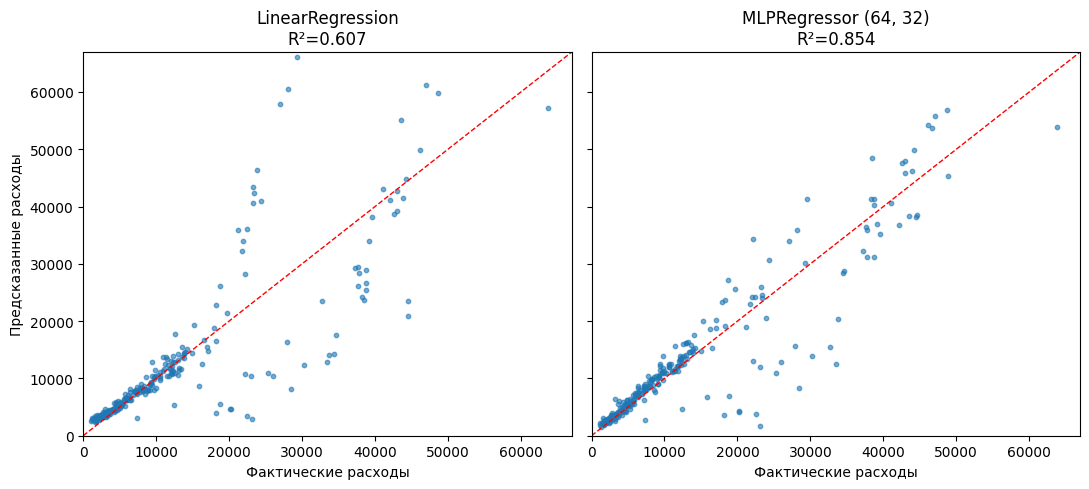

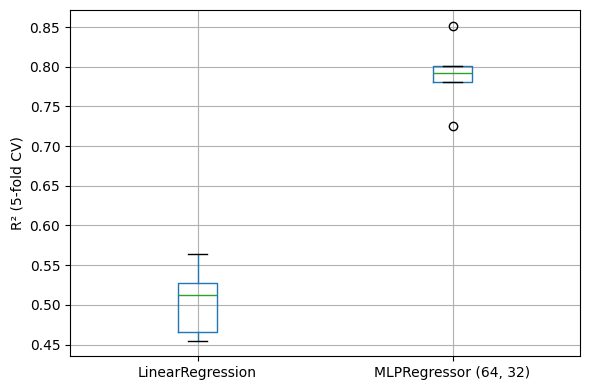

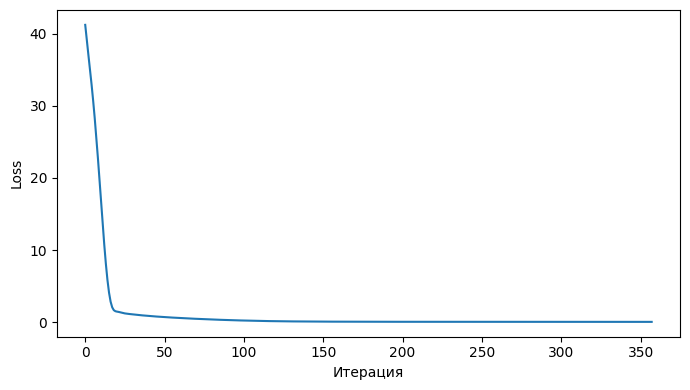

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
limits = [0, y_test.max() * 1.05]

for ax, result in zip(axes, results):
    ax.scatter(y_test, result['Предсказания'], s=10, alpha=0.6)
    ax.plot(limits, limits, 'r--', linewidth=1)
    ax.set_title(f"{result['Модель']}\nR²={result['R²']:.3f}")
    ax.set_xlabel('Фактические расходы')
    ax.set_xlim(limits)
    ax.set_ylim(limits)

axes[0].set_ylabel('Предсказанные расходы')
plt.tight_layout()
plt.show()

fold_df = pd.DataFrame({
    result['Модель']: result['CV R² по фолдам']
    for result in results
})
fold_df.boxplot(figsize=(6, 4))
plt.ylabel('R² (5-fold CV)')
plt.tight_layout()
plt.show()

mlp = mlp_model.named_steps['model'].regressor_
plt.figure(figsize=(7, 4))
plt.plot(mlp.loss_curve_)
plt.xlabel('Итерация')
plt.ylabel('Loss')
plt.tight_layout()
plt.show()


## 7. Сохранение результатов

In [16]:
results_df.to_csv('results.csv', index=False)
results_df.to_latex(
    'results.tex',
    index=False,
    float_format='%.4f',
    caption='Сравнение моделей прогноза страховых расходов',
    label='tab:results',
)
